# 03 · Bayesian Approach and Segment Analysis

**Objective:** complement the analysis from notebook 02 with two different questions:

1. **Bayesian approach:** what is the probability that one email outperforms another, and how much would be lost by choosing the wrong one? This answers more directly the question a marketing team asks than the p-value does.
2. **Segments (exploratory):** does the effect of each email change depending on the type of customer?

**Bayesian concepts used**
- **Prior:** what is assumed about the rate before seeing the data. Here a beta distribution is used; the uniform `Beta(1, 1)` considers all rates equally plausible.
- **Posterior:** what is known about the rate after seeing the data. With a beta prior and data of successes and failures, the posterior is also a beta, with an exact calculation.
- **95% credible interval:** range that contains the true value with 95% probability, *given what was observed and the prior*. Unlike the confidence interval, it is interpreted directly.
- **Probability of superiority:** probability, according to the posterior, that one group has a higher rate than another.
- **Expected loss:** how much is lost on average, in percentage points of conversion, if one option is chosen and it turns out the other was better.

Frequentists and Bayesians answer different questions: p-values and confidence intervals describe the behavior of a procedure if the experiment were repeated many times, while the posterior describes the uncertainty about the parameter given the data. With so many customers per group, both approaches are expected to reach similar conclusions.

## 1. Setup and data

The libraries, the functions from `src/ab.py` (including the Bayesian bootstrap and the heterogeneity test), and the data loading from `src/data.py` are imported. The seed (42) is set so that the simulations are reproducible.

In [63]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import load_hillstrom, prepare, GRUPOS
from src.ab import (
    compare_proportions, holm_adjust, bayesian_bootstrap_mean, heterogeneity_test,
)

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.dpi"] = 110
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

df = prepare(load_hillstrom())
n_group = df["group"].value_counts().reindex(GRUPOS)

COMPARACIONES = [("men", "control"), ("women", "control"), ("men", "women")]
ETIQUETA = {c: f"{c[0]} − {c[1]}" for c in COMPARACIONES}
N_SIM = 200_000  # simulations from the posterior distributions

## 2. Conversion: posterior of each group's rate

With a `Beta(1, 1)` prior, the posterior of the conversion rate of a group with `x` purchases among `n` customers is `Beta(1 + x, 1 + n − x)`. The mean and the 95% credible interval of each group are shown.

In [64]:
PRIOR = (1, 1)

def posterior_tasas(metrica, prior=PRIOR, n_sim=N_SIM):
    x = df.groupby("group", observed=True)[metrica].sum()
    n = df.groupby("group", observed=True)[metrica].size()
    return {g: stats.beta(prior[0] + x[g], prior[1] + n[g] - x[g]).rvs(n_sim, random_state=rng) for g in GRUPOS}

sim_conv = posterior_tasas("conversion")
tabla_post = pd.DataFrame({
    g: {"mean_%": 100 * s.mean(), "low_ic_%": 100 * np.percentile(s, 2.5), "high_ic_%": 100 * np.percentile(s, 97.5)}
    for g, s in sim_conv.items()
}).T
tabla_post.round(4)

,mean_%,low_ic_%,high_ic_%
control,0.5772,0.4797,0.6837
men,1.2574,1.1122,1.4112
women,0.8884,0.7668,1.0189


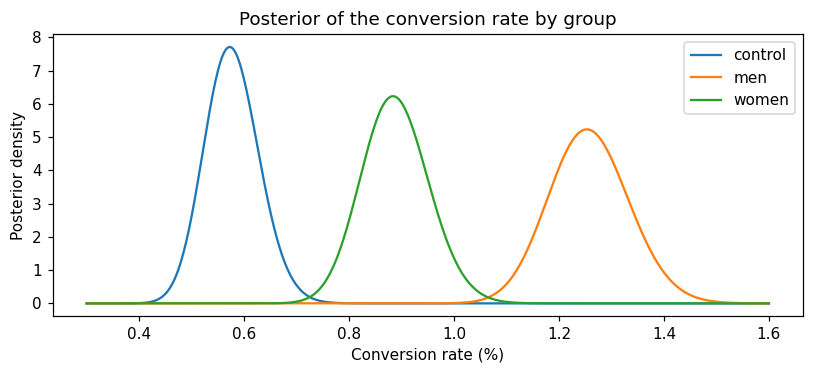

In [65]:
x_plot = np.linspace(0.003, 0.016, 500)
x_ev = df.groupby("group", observed=True)["conversion"].sum()

fig, ax = plt.subplots(figsize=(7.5, 3.5))
for g in GRUPOS:
    d = stats.beta(PRIOR[0] + x_ev[g], PRIOR[1] + n_group[g] - x_ev[g])
    ax.plot(100 * x_plot, d.pdf(x_plot) / 100, label=g)
ax.set_xlabel("Conversion rate (%)")
ax.set_ylabel("Posterior density")
ax.set_title("Posterior of the conversion rate by group")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Comparisons between groups

200,000 values are simulated from each posterior and compared in pairs (since the groups are independent, they can be subtracted directly). For each comparison, the following are reported:

- the **median** of the difference and its **95% credible interval**, in percentage points;
- the **probability of superiority** (how likely it is that the difference is greater than 0);
- the probability that the difference exceeds a **threshold of practical relevance**: the minimum detectable effect from notebook 02 (0.22 pp) is used, taken as the minimum difference worth considering;
- the **expected loss** of choosing each option: how many percentage points of conversion are lost, on average, if that option is chosen and the other was actually better.

In [66]:
UMBRAL_PP = 0.22  # minimum difference of interest (minimum detectable effect from notebook 02)

def comparar_bayes(sim, nombre_metrica):
    filas = []
    for a, b in COMPARACIONES:
        d = 100 * (sim[a] - sim[b])  # en pp
        filas.append({
            "metric": nombre_metrica,
            "comparison": ETIQUETA[(a, b)],
            "mean_dif_pp": np.median(d),
            "low_ic_pp": np.percentile(d, 2.5),
            "high_ic_pp": np.percentile(d, 97.5),
            "P(dif > 0)": (d > 0).mean(),
            f"P(dif > {UMBRAL_PP} pp)": (d > UMBRAL_PP).mean(),
            "expected_loss_if_choose_a_pp": np.maximum(-d, 0).mean(),
            "expected_loss_if_choose_b_pp": np.maximum(d, 0).mean(),
        })
    return pd.DataFrame(filas)

bayes_conv = comparar_bayes(sim_conv, "conversion")
bayes_conv.round(5)

,metric,comparison,mean_dif_pp,low_ic_pp,high_ic_pp,P(dif > 0),P(dif > 0.22 pp),expected_loss_if_choose_a_pp,expected_loss_if_choose_b_pp
0,conversion,men − control,0.67961,0.50029,0.86223,1.00000,1.00000,0.0,0.68013
1,conversion,women − control,0.31084,0.14935,0.47492,0.99988,0.86532,0.0,0.31121
2,conversion,men − women,0.36885,0.17396,0.56575,0.99992,0.93178,0.0,0.36893


**How to read the table:** in each row, `a` is the first group of the comparison and `b` the second. `pérdida_esperada_si_elijo_a_pp` is what is lost, on average, if `a` is chosen and `b` is actually better; a loss close to zero indicates that choosing that option carries practically no risk.

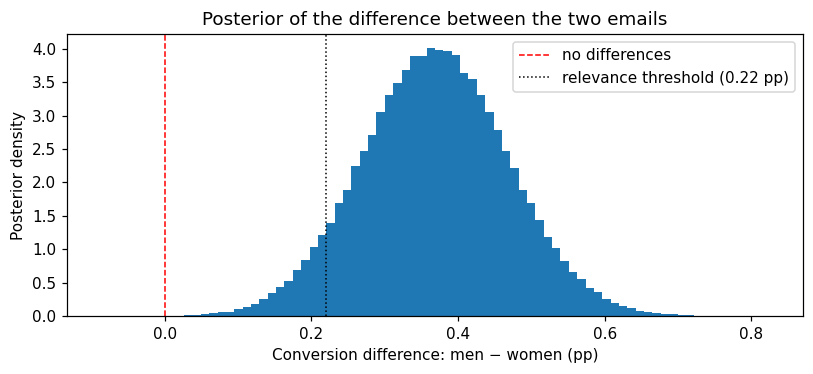

In [67]:
d_hm = 100 * (sim_conv["men"] - sim_conv["women"])

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.hist(d_hm, bins=80, density=True)
ax.axvline(0, color="red", linestyle="--", linewidth=1, label="no differences")
ax.axvline(UMBRAL_PP, color="black", linestyle=":", linewidth=1, label=f"relevance threshold ({UMBRAL_PP} pp)")
ax.set_xlabel("Conversion difference: men − women (pp)")
ax.set_ylabel("Posterior density")
ax.set_title("Posterior of the difference between the two emails")
ax.legend()
plt.tight_layout()
plt.show()

### 3.1 Prior sensitivity

The comparison between emails is repeated with three different priors to see how much that choice matters: a uniform one, the Jeffreys prior `Beta(0.5, 0.5)`, and an informative one centered on a rate of 0.6%, with a weight equivalent to 1,000 customers, `Beta(6, 994)`. With 21,000 customers per group, the data are expected to dominate and the prior to matter little.

In [68]:
priors = {"uniform Beta(1, 1)": (1, 1), "Jeffreys Beta(0,5; 0,5)": (0.5, 0.5), "informative Beta(6, 994)": (6, 994)}
filas = []
for nombre, pr in priors.items():
    s = posterior_tasas("conversion", prior=pr, n_sim=100_000)
    d = 100 * (s["men"] - s["women"])
    dc = 100 * (s["men"] - s["control"])
    filas.append({
        "prior": nombre,
        "median men − women (pp)": np.median(d),
        "P(men > women)": (d > 0).mean(),
        "median men − control (pp)": np.median(dc),
    })
pd.DataFrame(filas).round(4)

,prior,median men − women (pp),P(men > women),median men − control (pp)
0,"uniform Beta(1, 1)",0.3691,1.0000,0.6803
1,"Jeffreys Beta(0,5; 0,5)",0.3692,0.9999,0.6800
2,"informative Beta(6, 994)",0.3530,0.9999,0.6501


## 4. Visit (secondary)

The same comparison for the site visit, with the uniform prior.

In [69]:
sim_visit = posterior_tasas("visit")
bayes_visit = comparar_bayes(sim_visit, "visit")
bayes_visit.round(5)

,metric,comparison,mean_dif_pp,low_ic_pp,high_ic_pp,P(dif > 0),P(dif > 0.22 pp),expected_loss_if_choose_a_pp,expected_loss_if_choose_b_pp
0,visit,men − control,7.65649,6.99407,8.32043,1.0,1.0,0.0,7.6576
1,visit,women − control,4.52293,3.88787,5.15707,1.0,1.0,0.0,4.5229
2,visit,men − women,3.13514,2.42928,3.83983,1.0,1.0,0.0,3.1347


## 5. Spend per customer: Bayesian bootstrap

Spend cannot be modeled well with a standard distribution (99% zeros and a long tail). The **Bayesian bootstrap** avoids assuming a shape: each customer receives a random weight (from a Dirichlet distribution) and the weighted mean of spend is computed. Repeating this many times yields a posterior distribution of the mean without assuming normality. It is the Bayesian version of the bootstrap in notebook 02, and it is expected to give similar results.

In [70]:
gasto = {g: df.loc[df.group == g, "spend"].to_numpy() for g in GRUPOS}
sim_gasto = {g: bayesian_bootstrap_mean(gasto[g], 100_000, rng) for g in GRUPOS}

filas = []
for a, b in COMPARACIONES:
    d = sim_gasto[a] - sim_gasto[b]
    filas.append({
        "comparison": ETIQUETA[(a, b)],
        "median_dif_USD": np.median(d),
        "low_ic": np.percentile(d, 2.5),
        "high_ic": np.percentile(d, 97.5),
        "P(dif > 0)": (d > 0).mean(),
        "expected_loss_if_choose_a_USD": np.maximum(-d, 0).mean(),
        "expected_loss_if_choose_b_USD": np.maximum(d, 0).mean(),
    })
bayes_gasto = pd.DataFrame(filas)
bayes_gasto.round(4)

,comparison,median_dif_USD,low_ic,high_ic,P(dif > 0),expected_loss_if_choose_a_USD,expected_loss_if_choose_b_USD
0,men − control,0.7672,0.4891,1.0597,1.0000,0.0000,0.7693
1,women − control,0.4230,0.1688,0.6853,0.9995,0.0000,0.4242
2,men − women,0.3441,0.0331,0.6622,0.9850,0.0009,0.3460


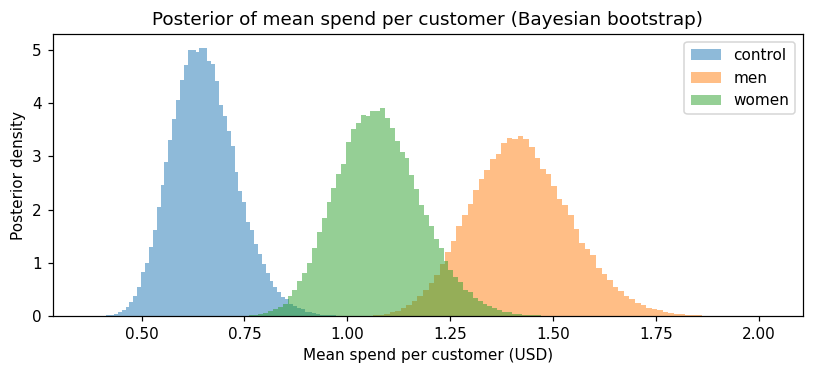

In [71]:
fig, ax = plt.subplots(figsize=(7.5, 3.5))
for g in GRUPOS:
    ax.hist(sim_gasto[g], bins=80, density=True, alpha=0.5, label=g)
ax.set_xlabel("Mean spend per customer (USD)")
ax.set_ylabel("Posterior density")
ax.set_title("Posterior of mean spend per customer (Bayesian bootstrap)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Does the effect change by customer type? (exploratory)

The effect of each email is compared across different segments defined with variables measured **before** the experiment: recency (months since the last purchase, in bins), spend history segment, zone, whether the customer is new, purchase channel, and affinity (whether in the last year they bought men's products, women's products, or both; in this dataset there are no customers who bought neither type).

**Caveats:**
- This analysis is **exploratory**: it serves to generate hypotheses, not to confirm them. Looking at many segments increases the probability of finding differences that are just chance.
- Conversion is a rare event, so within each segment there are few purchases and the estimates are imprecise: the intervals are wide.
- To assess whether the effect really varies across the segments of a variable, **Cochran's Q test** is used, which compares each segment's effect with the common effect. A low p-value indicates that the effect is not the same across all segments. This test has low power with rare events, so a high p-value does not prove that the effect is homogeneous. Multiple comparisons are corrected with Holm.

In [72]:
seg = df.copy()
seg["recency"] = pd.cut(seg["recency"], bins=[-np.inf, 3, 6, 9, np.inf], labels=["1-3", "4-6", "7-9", "10+"])
seg["history"] = seg["history_segment"]
seg["zone"] = seg["zip_code"]
seg["customer"] = seg["newbie"].map({1: "nuevo", 0: "existente"})
seg["channel"] = seg["channel"]
seg["affinity"] = np.select(
    [(seg.mens == 1) & (seg.womens == 0), (seg.womens == 1) & (seg.mens == 0), (seg.mens == 1) & (seg.womens == 1)],
    ["only men", "only women", "both"],
    default="nobody",
)
VARIABLES_SEG = ["recency", "history", "zone", "customer", "channel", "affinity"]

def efectos_por_segmento(var, metrica="conversion"):
    filas = []
    for cat, sub in seg.groupby(var, observed=True):
        x = sub.groupby("group", observed=True)[metrica].sum().reindex(GRUPOS, fill_value=0)
        n = sub.groupby("group", observed=True).size().reindex(GRUPOS, fill_value=0)
        fila = {"feature": var, "segment": str(cat),
                "n_control": int(n["control"]), "n_men": int(n["men"]), "n_women": int(n["women"]),
                "rate_control_%": 100 * x["control"] / n["control"],
                "rate_men_%": 100 * x["men"] / n["men"],
                "rate_women_%": 100 * x["women"] / n["women"]}
        for a, b in COMPARACIONES:
            r = compare_proportions(x[a], n[a], x[b], n[b])
            clave = f"{a[:3]}−{b[:3]}"
            fila[f"dif_{clave}_pp"] = 100 * r["diff"]
            fila[f"low_ic_{clave}"] = 100 * r["low_ic"]
            fila[f"high_ic_{clave}"] = 100 * r["high_ic"]
        filas.append(fila)
    return pd.DataFrame(filas)

seg_conv = pd.concat([efectos_por_segmento(v) for v in VARIABLES_SEG], ignore_index=True)
print("Segments analyzed:", len(seg_conv))
print("Minimum control group size within a segment:", int(seg_conv["n_control"].min()), "customers")

Segments analyzed: 22
Minimum control group size within a segment: 416 customers


### 6.1 Is there evidence that the effect varies?

Cochran's Q test for each segmentation variable and each comparison, on conversion and on visit (which, being more frequent, allows variation to be detected better). The Holm correction is applied within each metric.

In [73]:
def tabla_heterogeneidad(metrica):
    filas = []
    for var in VARIABLES_SEG:
        x = seg.groupby([var, "group"], observed=True)[metrica].sum().unstack().reindex(columns=GRUPOS, fill_value=0)
        n = seg.groupby([var, "group"], observed=True)[metrica].size().unstack().reindex(columns=GRUPOS, fill_value=0)
        for a, b in COMPARACIONES:
            r = heterogeneity_test(x[a], n[a], x[b], n[b])
            filas.append({"metric": metrica, "feature": var, "comparison": ETIQUETA[(a, b)],
                          "Q": r["Q"], "gl": r["gl"], "p_value": r["p_value"]})
    t = pd.DataFrame(filas)
    t["p_holm"] = holm_adjust(t["p_value"])
    return t

het = pd.concat([tabla_heterogeneidad("conversion"), tabla_heterogeneidad("visit")], ignore_index=True)
het.round(4)

,metric,feature,comparison,Q,gl,p_value,p_holm
0,conversion,recency,men − control,1.3912,3,0.7076,1.0000
1,conversion,recency,women − control,0.6061,3,0.8950,1.0000
2,conversion,recency,men − women,1.1391,3,0.7677,1.0000
3,conversion,history,men − control,7.3864,6,0.2866,1.0000
4,conversion,history,women − control,13.1662,6,0.0405,0.5666
5,conversion,history,men − women,16.7419,6,0.0103,0.1748
6,conversion,zone,men − control,0.5657,2,0.7536,1.0000
7,conversion,zone,women − control,0.3682,2,0.8318,1.0000
8,conversion,zone,men − women,1.2154,2,0.5446,1.0000
9,conversion,customer,men − control,0.4144,1,0.5197,1.0000


### 6.2 Effects by segment (conversion)

Difference in conversion of each email versus the control in each segment, with its 95% confidence interval (percentage points). Bars that cross the red line indicate that, in that segment, the difference is not distinguishable from zero with these data.

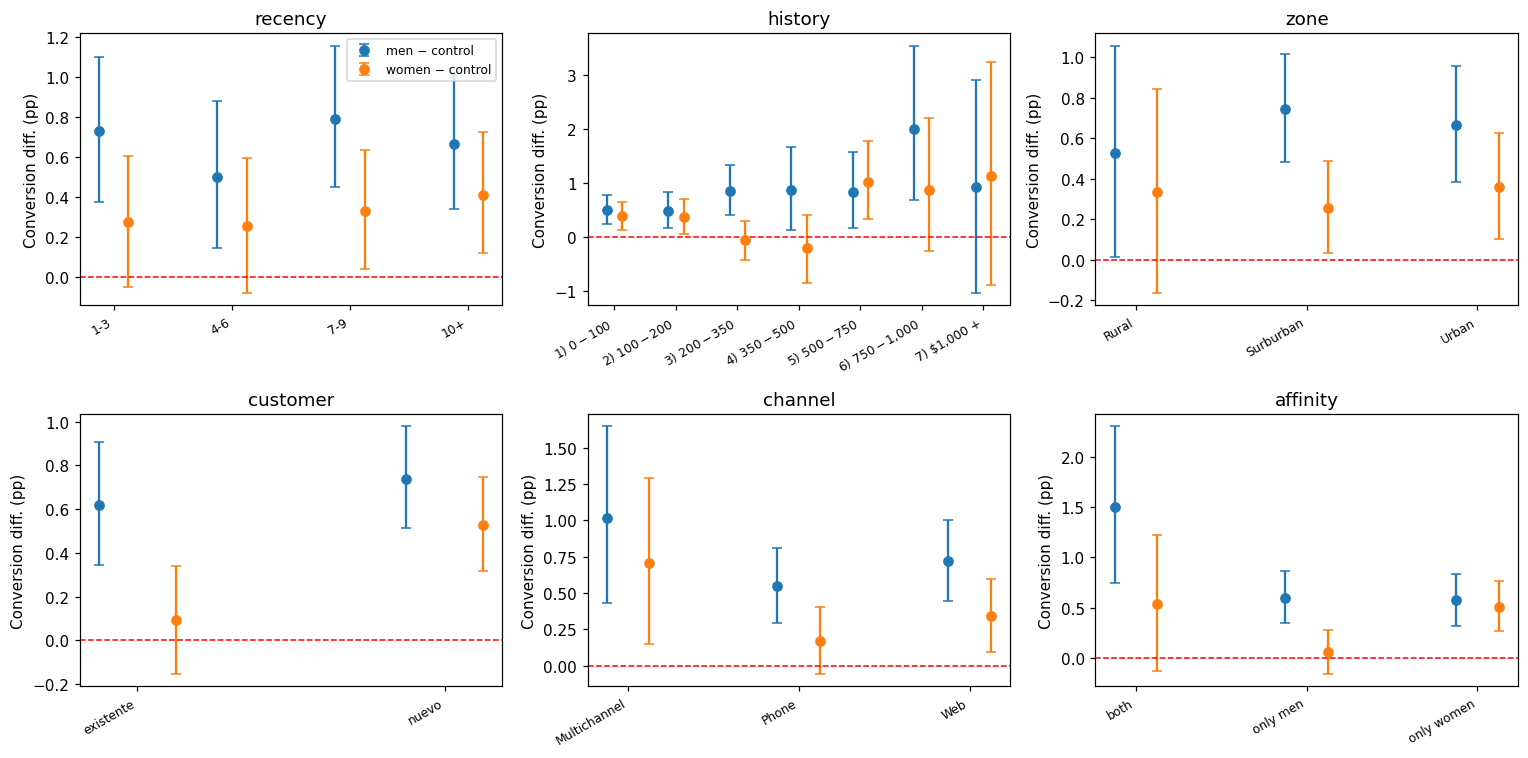

In [74]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, var in zip(axes.ravel(), VARIABLES_SEG):
    t = seg_conv[seg_conv["feature"] == var].reset_index(drop=True)
    pos = np.arange(len(t))
    for k, (clave, color, lab) in enumerate([("men−con", "tab:blue", "men − control"), ("wom−con", "tab:orange", "women − control")]):
        y = t[f"dif_{clave}_pp"]
        ax.errorbar(pos + (k - 0.5) * 0.25, y,
                    yerr=[y - t[f"low_ic_{clave}"], t[f"high_ic_{clave}"] - y],
                    fmt="o", capsize=3, color=color, label=lab)
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xticks(pos)
    ax.set_xticklabels(t["segment"], rotation=30, ha="right", fontsize=8)
    ax.set_title(var)
    ax.set_ylabel("Conversion diff. (pp)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [75]:
cols = ["feature", "segment", "n_control", "rate_control_%", "rate_men_%", "rate_women_%",
        "dif_men−con_pp", "dif_wom−con_pp", "dif_men−wom_pp"]
seg_conv[cols].round(3)

,feature,segment,n_control,rate_control_%,rate_men_%,rate_women_%,dif_men−con_pp,dif_wom−con_pp,dif_men−wom_pp
0,recency,1-3,7438,0.901,1.633,1.176,0.733,0.275,0.458
1,recency,4-6,4766,0.546,1.049,0.799,0.503,0.254,0.249
2,recency,7-9,4699,0.340,1.131,0.670,0.790,0.329,0.461
3,recency,10+,4403,0.295,0.960,0.708,0.665,0.413,0.253
4,history,1) $0 - $100,7612,0.420,0.919,0.799,0.499,0.379,0.120
5,history,2) $100 - $200,4836,0.414,0.895,0.783,0.482,0.369,0.113
6,history,3) $200 - $350,4044,0.692,1.540,0.626,0.848,-0.067,0.915
7,history,4) $350 - $500,2124,1.130,2.003,0.914,0.873,-0.216,1.089
8,history,5) $500 - $750,1652,0.545,1.378,1.564,0.833,1.020,-0.187
9,history,"6) $750 - $1,000",622,0.482,2.484,1.349,2.002,0.867,1.135


### 6.3 Effect on visits by affinity

The heterogeneity test on visits (section 6.1) detects a very pronounced variation according to customer affinity. The effect of each email on **visits** is shown for each affinity group. This is an exploratory finding: affinity was one of the six segmentation variables defined in advance, and the result holds after the Holm correction, but a visit is an intermediate step and is not equivalent to revenue.

In [76]:
afin_visit = efectos_por_segmento("affinity", "visit")
afin_visit[["segment", "n_control", "rate_control_%", "rate_men_%", "rate_women_%",
            "dif_men−con_pp", "dif_wom−con_pp", "dif_men−wom_pp"]].round(3)

,segment,n_control,rate_control_%,rate_men_%,rate_women_%,dif_men−con_pp,dif_wom−con_pp,dif_men−wom_pp
0,both,2149,18.055,31.499,25.165,13.444,7.110,6.334
1,only men,9638,9.981,16.897,11.089,6.916,1.108,5.808
2,only women,9519,9.581,16.639,16.979,7.058,7.399,-0.341


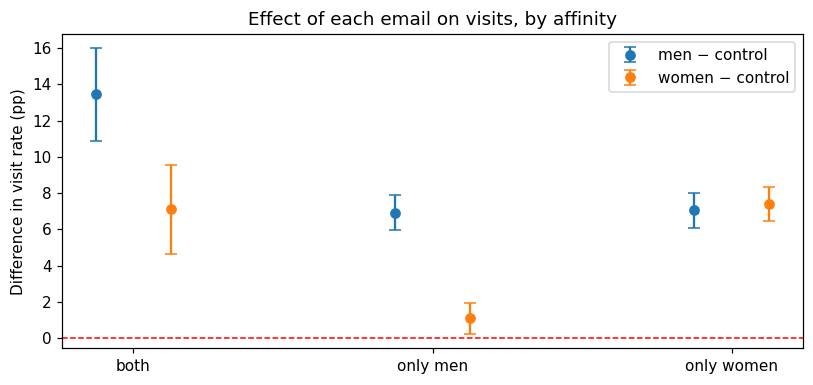

In [77]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
pos = np.arange(len(afin_visit))
for k, (clave, color, lab) in enumerate([("men−con", "tab:blue", "men − control"),
                                         ("wom−con", "tab:orange", "women − control")]):
    y = afin_visit[f"dif_{clave}_pp"]
    ax.errorbar(pos + (k - 0.5) * 0.25, y,
                yerr=[y - afin_visit[f"low_ic_{clave}"], afin_visit[f"high_ic_{clave}"] - y],
                fmt="o", capsize=4, color=color, label=lab)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xticks(pos)
ax.set_xticklabels(afin_visit["segment"])
ax.set_ylabel("Difference in visit rate (pp)")
ax.set_title("Effect of each email on visits, by affinity")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Save results

The notebook tables are saved in `reports/`: Bayesian comparisons (`resultados_bayesiano.csv` and `resultados_bayesiano_gasto.csv`), effects by segment (`efectos_por_segmento.csv`), heterogeneity tests (`heterogeneidad.csv`), and the effect on visits by affinity (`afinidad_visita.csv`).

In [78]:
pd.concat([bayes_conv, bayes_visit], ignore_index=True).to_csv(
    os.path.join(ROOT, "reports", "resultados_bayesiano.csv"), index=False)
bayes_gasto.to_csv(os.path.join(ROOT, "reports", "resultados_bayesiano_gasto.csv"), index=False)
seg_conv.to_csv(os.path.join(ROOT, "reports", "efectos_por_segmento.csv"), index=False)
afin_visit.to_csv(os.path.join(ROOT, "reports", "afinidad_visita.csv"), index=False)
het.to_csv(os.path.join(ROOT, "reports", "heterogeneidad.csv"), index=False)
print("Results saved in reports/")

Results saved in reports/


## 8. Conclusions

- **Conversion (Bayesian):** the men's email raises conversion by 0.68 pp relative to the control (95% credible interval: 0.50 to 0.86) and the women's email by 0.31 pp (0.15 to 0.47). The difference between emails is 0.37 pp in favor of the men's email (0.17 to 0.57). The probability of superiority is greater than 99.9% in all three comparisons, and the probability that the difference exceeds 0.22 pp (the minimum detectable effect from notebook 02) is 100%, 87%, and 93%.
- **Decision between emails:** choosing the men's email has an expected loss of practically 0 pp of conversion; choosing the women's email, 0.37 pp.
- **Prior sensitivity:** with a uniform prior, the Jeffreys prior, and an informative one centered on 0.6%, the median of the men − women difference ranges from 0.353 to 0.369 pp and the probability of superiority is 99.99% or higher. With 21,000 customers per group, the data dominate and the conclusions do not depend on the prior.
- **Visits:** the probability of superiority is 100% in all three comparisons, with differences of 7.7 pp (men − control), 4.5 pp (women − control), and 3.1 pp (men − women).
- **Spend per customer (Bayesian bootstrap):** the men's email adds 0.77 dollars per customer versus the control (0.49 to 1.06) and the women's email, 0.42 (0.17 to 0.69). The advantage of men's over women's is 0.34 dollars (0.03 to 0.66), with a probability of superiority of 98.5%. The expected loss of choosing the women's email is 0.35 dollars per customer, versus 0.001 if the men's email is chosen. The results differ from the frequentist analysis by less than 0.01 dollars.
- **Heterogeneity in conversion:** none of the 18 Cochran's Q tests is significant after the Holm correction (the smallest adjusted p-value is 0.15). Five of the 18 raw p-values are below 0.05, more than would be expected by chance, but the test has low power with rare events, so it cannot be concluded either that the effect is homogeneous or that it varies.
- **Heterogeneity in visits (affinity, section 6.3):** the effect of the emails on visits varies by customer affinity (adjusted p ≤ 0.0001 in all three comparisons; affinity was one of the six variables defined in advance). Among those who only bought men's products, the women's email raises visits by only +1.1 pp (from 10.0% to 11.1%), versus +7.4 pp among those who only bought women's products (from 9.6% to 17.0%). The men's email works in all groups (+6.9 pp, +7.1 pp, and +13.4 pp) and among those who only bought women's products it performs the same as the women's email (−0.3 pp difference). Customers who bought both types of products are the most receptive: they have the highest visit rate without an email (18.1%) and the largest effects. In conversion, the pattern points in the same direction (+0.06 pp from the women's email among those who only bought men's products, versus +0.51 pp among those who only bought women's products), but the heterogeneity test was not significant. This is an exploratory finding that suggests testing, in a new experiment, not sending the women's email to those who only bought men's products.
- **Descriptive patterns in conversion (exploratory):** the men's email has a positive effect in all 22 segments (from +0.48 to +2.00 pp). The women's email is positive in almost all of them, with effects between 0.06 and 1.13 pp, except in two spend history bins ($200 to $500), where the effect is −0.07 and −0.22 pp. Among customers who bought only men's products, the women's email yields +0.06 pp, versus +0.51 pp among those who bought only women's products. Control conversion drops from 0.90% (recency of 1 to 3 months) to 0.30% (10 months or more); the absolute effect of the men's email is similar across all bins (0.50 to 0.79 pp), so the relative increase is larger among less recent customers.
- **Limitations of the segment analysis:** it is exploratory and serves to generate hypotheses. Some segments have very few purchases (for example, the control for the $750 to $1,000 spend history bin has 622 customers and about 3 purchases), so their intervals are very wide and should not be interpreted. Knowing which customers should receive each email would require an uplift model, which is beyond the scope of this analysis.
- **General limitations:** gross revenue without costs or margins, follow-up of only two weeks, a sample of customers who purchased in the last 12 months, and the two emails differ in content and audience at the same time.